<a href="https://colab.research.google.com/github/MarceloCoccaro12/Disciplina_de_Inteligencia_Artificial_UMC/blob/main/fertilizantes_summit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fazendo a conecção com o Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Importar as bibliotecas

In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Carregar o dataset
https://www.kaggle.com/datasets/miadul/fertilizer-recommendation-dataset

In [ ]:
fertilizante = pd.read_csv('/content/drive/MyDrive/arquivos/fertilizer_recommendation.csv')

In [ ]:
fertilizante

,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Nitrogen_Level,Phosphorus_Level,Potassium_Level,Temperature,Humidity,Rainfall,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Previous_Crop,Region,Fertilizer_Used_Last_Season,Yield_Last_Season,Recommended_Fertilizer
0,Clay,6.07,34.98,0.32,1.87,61,44,84,19.84,83.31,1693.22,Cotton,Harvest,Kharif,Canal,Wheat,South,297.15,1.19,MOP
1,Silt,6.39,47.34,0.28,0.21,59,56,18,24.40,46.27,1030.21,Maize,Vegetative,Kharif,Sprinkler,Potato,Central,77.17,4.40,Urea
2,Sandy,7.92,38.13,0.99,1.88,43,21,119,24.82,71.86,1166.16,Cotton,Flowering,Kharif,Rainfed,Tomato,South,128.93,7.21,Urea
3,Clay,5.86,14.17,1.46,0.36,88,46,34,27.87,53.23,2881.83,Wheat,Flowering,Zaid,Sprinkler,Potato,West,233.96,1.85,MOP
4,Clay,7.98,19.28,0.85,2.16,104,53,98,24.17,51.87,714.84,Potato,Sowing,Kharif,Rainfed,Maize,East,214.39,7.36,Zinc Sulphate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,Silt,7.10,26.37,0.76,0.66,89,20,69,22.07,42.75,1857.78,Maize,Sowing,Kharif,Drip,Sugarcane,West,57.12,6.81,DAP
9996,Clay,5.21,46.35,0.80,1.03,40,28,99,16.40,41.74,858.69,Tomato,Harvest,Zaid,Drip,Maize,West,85.12,1.25,Urea
9997,Loamy,4.70,56.16,0.89,1.12,51,71,61,27.01,44.82,544.08,Tomato,Harvest,Rabi,Canal,Cotton,East,218.88,1.74,Urea
9998,Loamy,7.23,41.86,1.46,0.93,152,81,94,24.64,43.27,1510.97,Sugarcane,Vegetative,Rabi,Drip,Rice,West,240.37,3.70,NPK


# Verificação valos nulos

In [ ]:
fertilizante.isnull().sum()

,0
Soil_Type,0
Soil_pH,0
Soil_Moisture,0
Organic_Carbon,0
Electrical_Conductivity,0
Nitrogen_Level,0
Phosphorus_Level,0
Potassium_Level,0
Temperature,0
Humidity,0


# Verificação de valores unicas da coluna "Recommended_Fertilizer"

In [90]:
verificar_valores_unicos = fertilizante['Recommended_Fertilizer'].unique()
print(verificar_valores_unicos)

['MOP' 'Urea' 'Zinc Sulphate' 'Compost' 'NPK' 'DAP' 'SSP']


# Carregamento e Preparação dos Dados

In [ ]:
X = fertilizante.drop('Recommended_Fertilizer', axis=1)
y = fertilizante['Recommended_Fertilizer']

# Dividindo as features em Categorical e Numerical

In [ ]:
categorical_features = [
    'Soil_Type',
    'Crop_Type',
    'Crop_Growth_Stage',
    'Season',
    'Irrigation_Type',
    'Previous_Crop',
    'Region'
]

numerical_features = [
    'Soil_pH',
    'Soil_Moisture',
    'Organic_Carbon',
    'Electrical_Conductivity',
    'Nitrogen_Level',
    'Phosphorus_Level',
    'Potassium_Level',
    'Temperature',
    'Humidity',
    'Rainfall',
    'Fertilizer_Used_Last_Season',
    'Yield_Last_Season'
]

# Tranformar numerical em `StandartScaler()` e categorical em `OneHotEncoder()`

In [ ]:
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

# Definição do `ColumnTransformer()`

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)

# Criação e Treinamento do Modelo SVM utilizando o Pipeline

In [ ]:
model_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                 ('regressor', SVC(kernel='linear'))])

# Divisão dos Dados em Treino e Teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Previsão com Modelo Treinado

In [ ]:
model_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['Soil_pH', 'Soil_Moisture',
                                                   'Organic_Carbon',
                                                   'Electrical_Conductivity',
                                                   'Nitrogen_Level',
                                                   'Phosphorus_Level',
                                                   'Potassium_Level',
                                                   'Temperature', 'Humidity',
                                                   'Rainfall',
                                                   'Fertilizer_Used_Last_Season',
                                                   'Yield_Last_Season']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Soil_Type', 'Crop_Type',
                                                   'Crop_Growth_Stage',
                                                   'Season', 'Irrigation_Type',
                                                   'Previous_Crop',
                                                   'Region'])])),
                ('regressor', SVC(kernel='linear'))])

# Avaliação do Modelo

In [ ]:
y_pred = model_pipeline.predict(X_test)


# Acurácia do Modelo

In [ ]:
acuracia = accuracy_score(y_test, y_pred)
print(f"Acurácia do modelo: {acuracia * 100:.2f}%")

Acurácia do modelo: 79.85%


# Visualização das Previsões

In [ ]:
fert_recomendado = pd.DataFrame({'Atual': y_test, 'Predito': y_pred, 'Correto': y_test == y_pred})
print("\nAlguns valores Reais vs. Previstos:")
print(fert_recomendado)


Alguns valores Reais vs. Previstos:
              Atual        Predito  Correto
6252  Zinc Sulphate  Zinc Sulphate     True
4684            DAP            DAP     True
1731            DAP            DAP     True
4742           Urea           Urea     True
4521           Urea           Urea     True
...             ...            ...      ...
6412            MOP        Compost    False
8285  Zinc Sulphate  Zinc Sulphate     True
7853            NPK            DAP    False
1095            DAP           Urea    False
6929           Urea           Urea     True

[2000 rows x 3 columns]


# Utilizando o GridSearchCV

In [ ]:
# Definir a grade de parâmetros para o SVC
# Estes são apenas valores de exemplo, você pode ajustá-los
param_grid = {
    'regressor__C': [0.1, 1, 10, 100],
    'regressor__gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'regressor__kernel': ['linear', 'poly', 'rbf', 'sigmoid']
}

print("Iniciando a otimização de hiperparâmetros com GridSearchCV...")
grid_search = GridSearchCV(
    model_pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    verbose=2,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_

print(f"\n--- Resultados da Otimização de Hiperparâmetros ---")
print(f"Melhores parâmetros encontrados: {best_params}")
print(f"Melhor Acurácia Média (Validação Cruzada): {best_score * 100:.2f}%")

# Avaliar o melhor modelo no conjunto de teste
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

# Calcular a acurácia de teste
acuracia_teste = accuracy_score(y_test, y_pred_tuned)

print(f"Acurácia do modelo otimizado no conjunto de teste: {acuracia_teste * 100:.2f}%")

# Exibir métricas detalhadas (Precisão, Recall, F1-Score)
print("\n--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred_tuned))

Iniciando a otimização de hiperparâmetros com GridSearchCV...
Fitting 5 folds for each of 80 candidates, totalling 400 fits

--- Resultados da Otimização de Hiperparâmetros ---
Melhores parâmetros encontrados: {'regressor__C': 10, 'regressor__gamma': 0.01, 'regressor__kernel': 'rbf'}
Melhor Acurácia Média (Validação Cruzada): 80.56%
Acurácia do modelo otimizado no conjunto de teste: 80.55%

--- Relatório de Classificação ---
               precision    recall  f1-score   support

      Compost       0.66      0.68      0.67       191
          DAP       0.86      0.91      0.89       607
          MOP       0.78      0.76      0.77       284
          NPK       0.73      0.56      0.63       127
          SSP       0.33      0.06      0.10        36
         Urea       0.85      0.91      0.88       606
Zinc Sulphate       0.65      0.61      0.63       149

     accuracy                           0.81      2000
    macro avg       0.70      0.64      0.65      2000
 weighted avg      

# Matriz de Confusão

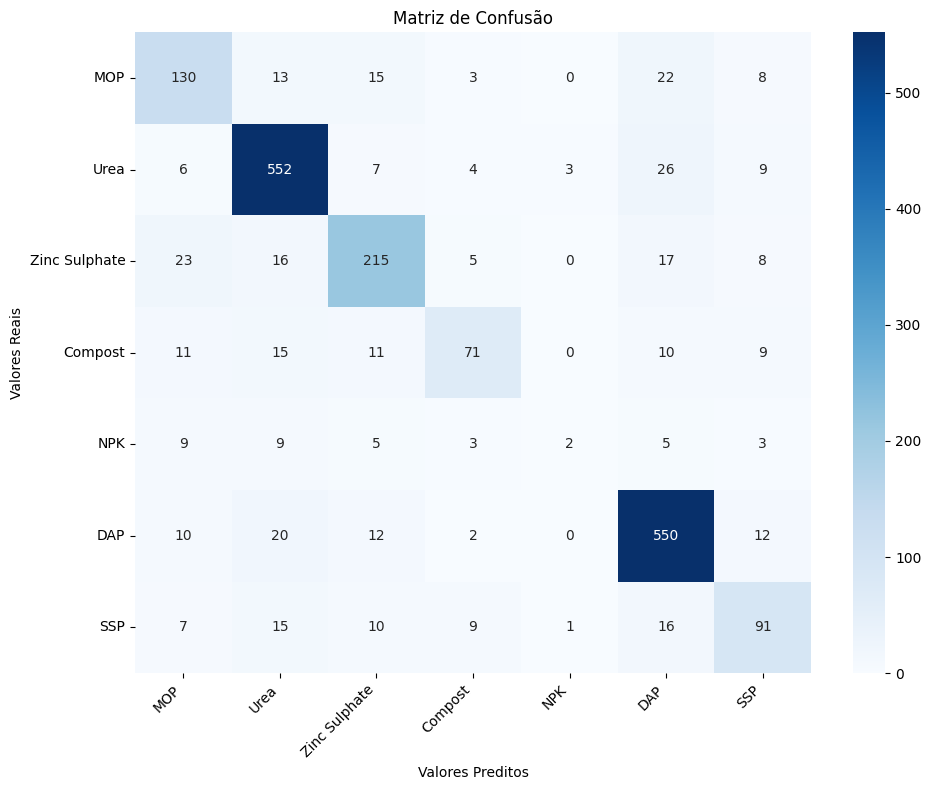

In [98]:
classes = ['MOP', 'Urea', 'Zinc Sulphate', 'Compost', 'NPK', 'DAP', 'SSP']

cm = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes,
)

# Rotação para legibilidade no eixo X e Y
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.xlabel('Valores Preditos')
plt.ylabel('Valores Reais')
plt.title('Matriz de Confusão')

plt.tight_layout()
plt.show()